In [1]:
from config import Config, NetworkKind
from lib import SweepPoint, sweep
from plot import plot_grid_search

results = {}


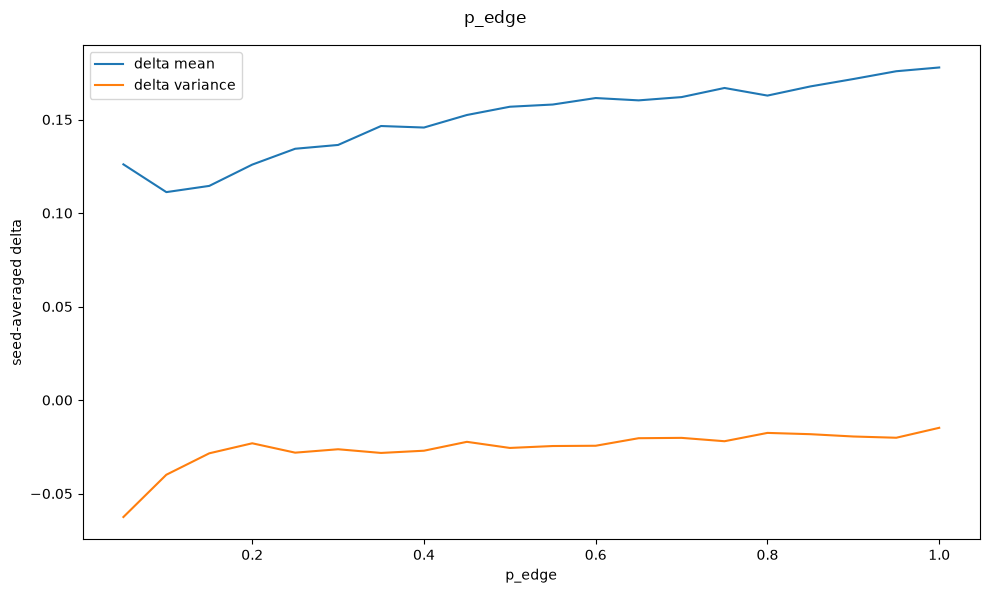

In [2]:
STEP_SIZE = 4
n_agents = Config().n_agents
seeds = range(100)

results[NetworkKind.RANDOM] = sweep(
    NetworkKind.RANDOM,
    [SweepPoint(p_edge=step / 20) for step in range(1, 21)],
    seeds,
)
plot_grid_search(results[NetworkKind.RANDOM], "p_edge")


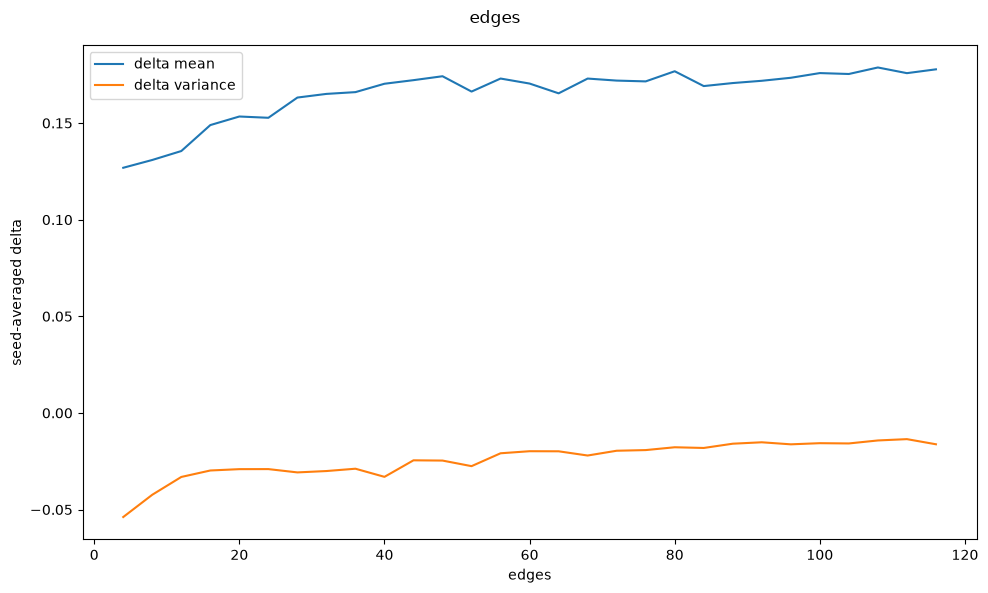

In [3]:
results[NetworkKind.BARBASI] = sweep(
    NetworkKind.BARBASI,
    [SweepPoint(edges=edges) for edges in range(STEP_SIZE, n_agents, STEP_SIZE)],
    seeds,
)
plot_grid_search(results[NetworkKind.BARBASI], "edges")


In [ ]:
results[NetworkKind.WATTS] = sweep(
    NetworkKind.WATTS,
    [
        SweepPoint(k_neighbors=neighbors, p_rewire=step / 20)
        for neighbors in range(STEP_SIZE, n_agents, STEP_SIZE)
        for step in range(21)
    ],
    seeds,
)
plot_grid_search(results[NetworkKind.WATTS], "k_neighbors", "p_rewire")


In [ ]:
for kind, summary in results.items():
    print(kind)
    print(summary)


random
SweepResult(highest_delta_mean=0.17848000969111516, average_delta_mean=0.15142319012909108, variance_delta_mean=0.0003796062936585842, average_delta_variance=-0.026710662721345174, seed_means=[0.20028870961291015, 0.14463820030410043, 0.17472414236559453, 0.16145588177992706, 0.19248056979201372, 0.13865214745265347, 0.14545757124560538, 0.20510016054200783, 0.18595060967905722, 0.19680824066163466, 0.10389548039912133, 0.1474508412346779, 0.17488680725401037, 0.19560004638581246, 0.13333201973378633, 0.12756096769787034, 0.1692314061565202, 0.11395839065973878, 0.1219189616007325, 0.11729510601129542, 0.1640279876169978, 0.11777310543619128, 0.10776299467349788, 0.16208047249630075, 0.1623175255441157, 0.16505404299920212, 0.07787267101141052, 0.14973391855885895, 0.16882410241871276, 0.12313896242453981, 0.2012633262861944, 0.18333716123400068, 0.17044843318947392, 0.17408194159465093, 0.13650915658592158, 0.06903177238431552, 0.11847536569948428, 0.14333746056698107, 0.157986

In [ ]:
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

random_vs_barbasi = ttest_rel(
    results[NetworkKind.RANDOM].seed_means,
    results[NetworkKind.BARBASI].seed_means,
)
random_vs_watts = ttest_rel(
    results[NetworkKind.RANDOM].seed_means,
    results[NetworkKind.WATTS].seed_means,
)
barbasi_vs_watts = ttest_rel(
    results[NetworkKind.BARBASI].seed_means,
    results[NetworkKind.WATTS].seed_means,
)
adjusted = multipletests(
    [random_vs_barbasi.pvalue, random_vs_watts.pvalue, barbasi_vs_watts.pvalue],
    method="holm",
)[1]
print("random vs barbasi:", random_vs_barbasi, "Holm p:", adjusted[0])
print("random vs watts:", random_vs_watts, "Holm p:", adjusted[1])
print("barbasi vs watts:", barbasi_vs_watts, "Holm p:", adjusted[2])


random vs barbasi: TtestResult(statistic=np.float64(-4.8514057972702345), pvalue=np.float64(4.5668974564179594e-06), df=np.int64(99)) Holm p: 9.133794912835919e-06
random vs watts: TtestResult(statistic=np.float64(1.3370034242903508), pvalue=np.float64(0.18428564763894373), df=np.int64(99)) Holm p: 0.18428564763894373
barbasi vs watts: TtestResult(statistic=np.float64(6.681247685264781), pvalue=np.float64(1.4017872820276817e-09), df=np.int64(99)) Holm p: 4.205361846083046e-09


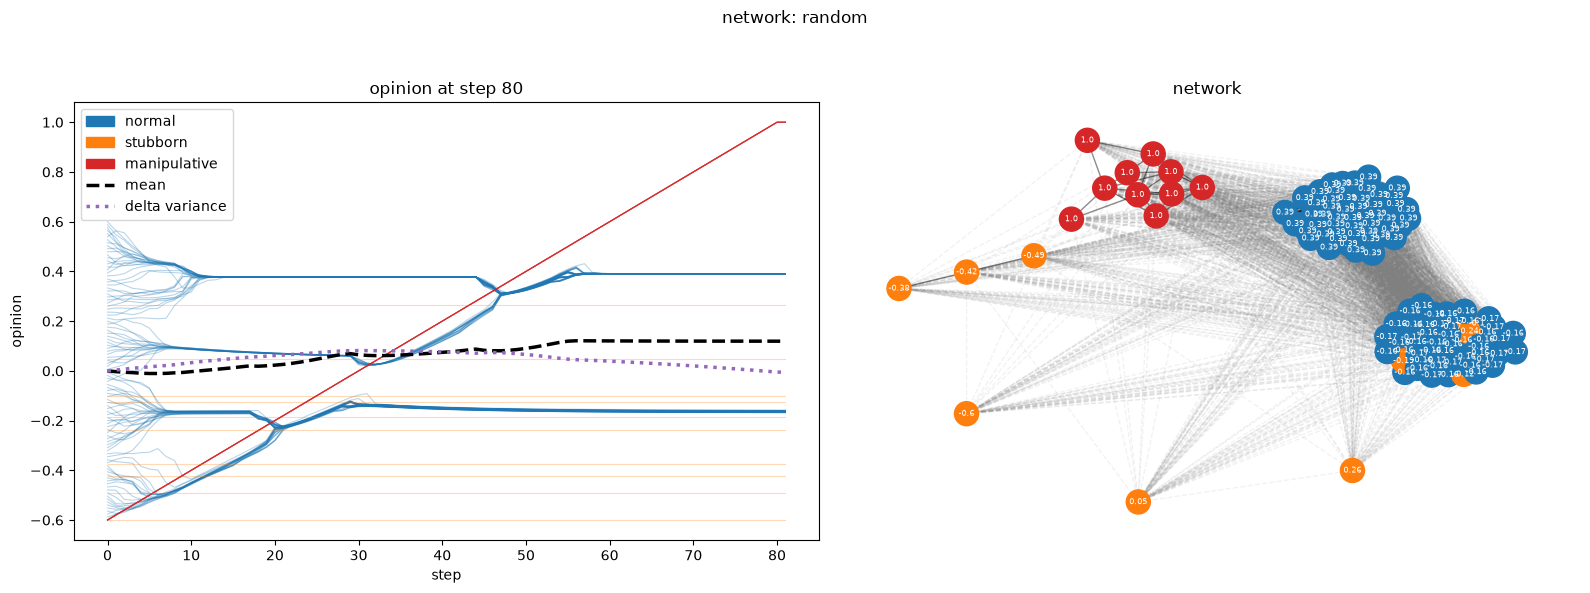

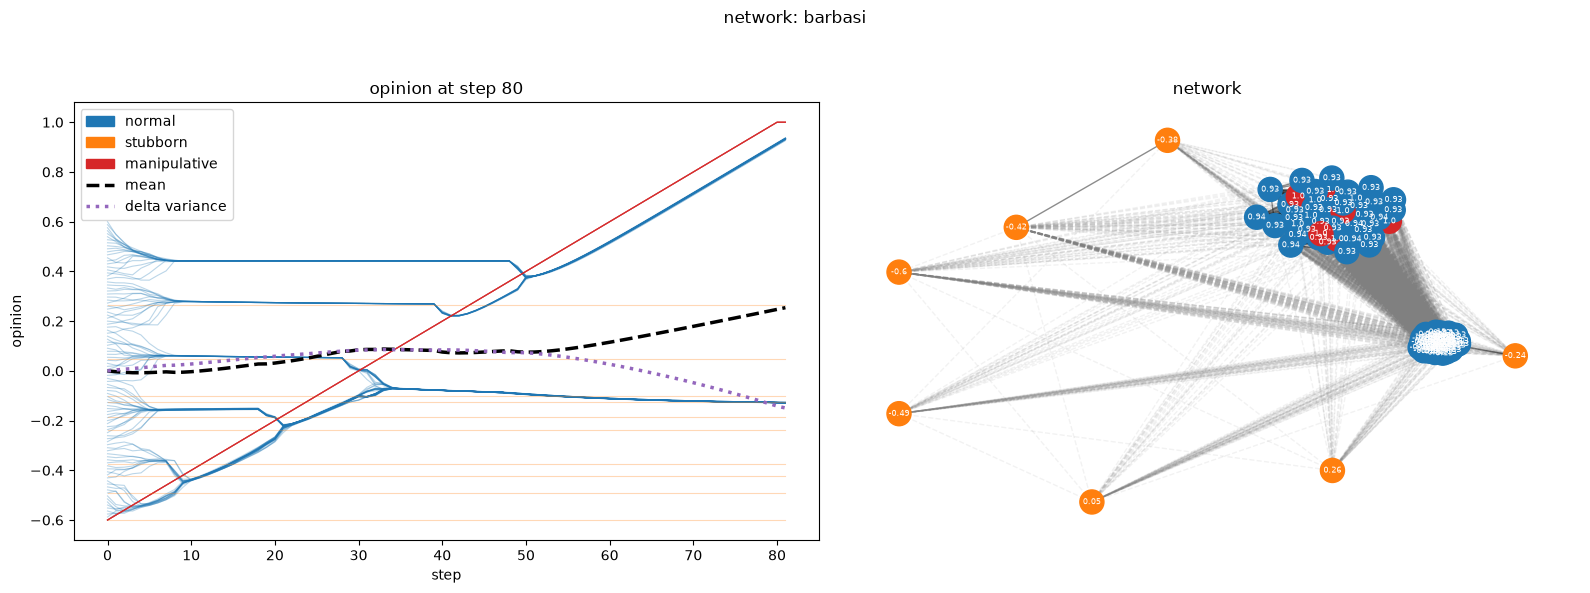

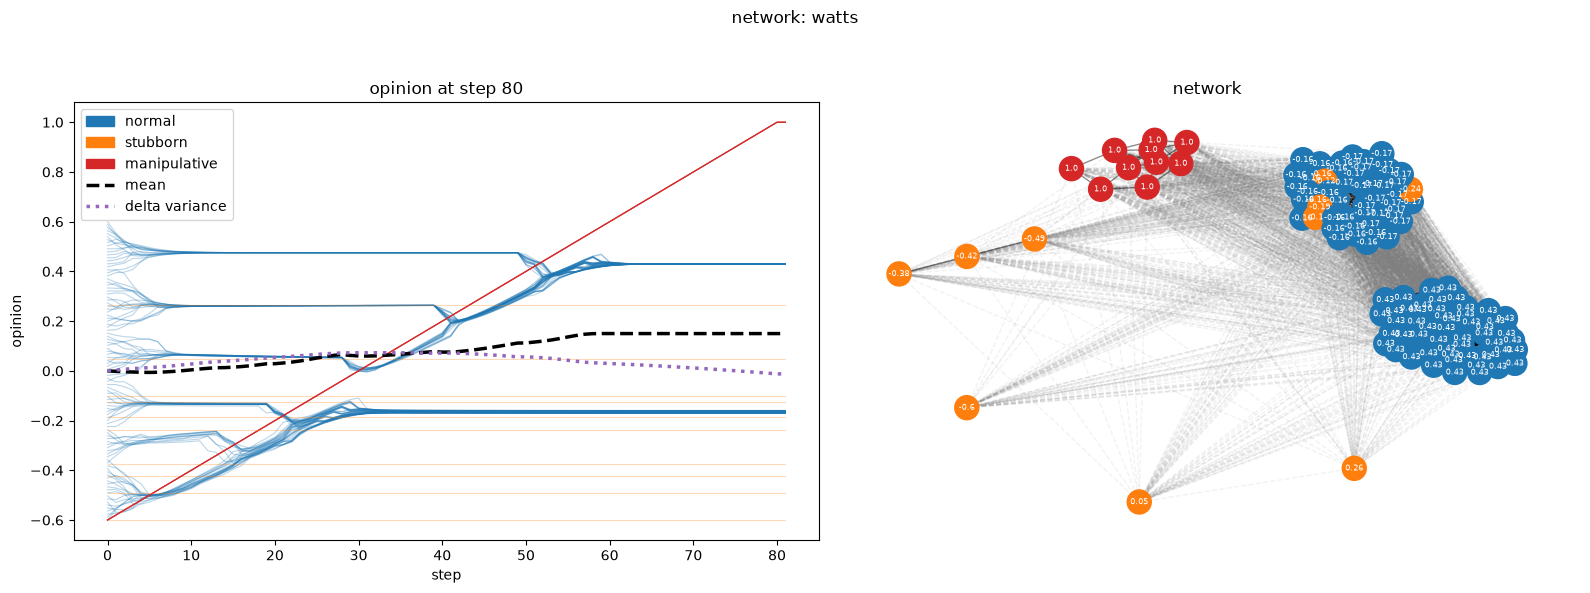

In [ ]:
from config import Config
from lib import init_sim, run_one

STEP_SIZE = 4
cfg = Config()
for kind in cfg.networks:
    sim = init_sim(cfg, kind)
    run_one(cfg, sim, True)
